# 02 — Identifikasi elemen & format data (Bab 4.1)

**Tujuan:** mengetahui isi data PNW-ML yang *sebenarnya* (bukan dari proposal) sebelum membersihkan apa pun.

Notebook ini menjawab tugas no. 6: *"identifikasi elemen dari setiap data tersebut dan formatnya, apakah terstruktur, semi-terstruktur, atau tidak terstruktur"*.

| Bagian | Isi | Output ke `outputs/tables/` |
|---|---|---|
| 0 | Kenapa 3 file ini yang dipakai | — |
| A | Metadata CSV (dibaca **Spark** dari HDFS raw zone) | `column_comparison.md`, `class_counts.md`, `null_percent.md`, `label_crosstab.md` |
| B | Waveform HDF5 (dibaca **h5py lewat WebHDFS** dari raw zone) | `hdf5_structure.md`, `orphans.md`, `figures/waveform_*.png` |
| C | Klasifikasi format (structured / semi / unstructured) | `data_elements.md` |
| D | Kolom mana yang boleh jadi fitur model? (bukti leakage) | `leakage_evidence.md`, `column_roles.md` |
| E | Kamus data (README tiap kolom) + pertanyaan awal tentang data | `data_dictionary.md`, `initial_data_questions.md` |

Syarat: HDFS jalan (`jps` → NameNode + DataNode).

In [1]:
import sys, os, re, time
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import pandas as pd, numpy as np, h5py, matplotlib.pyplot as plt
from pyspark.sql import functions as F
pd.set_option('display.max_rows', 200, 'display.max_columns', 50, 'display.width', 200)
os.makedirs(OUT_FIGS, exist_ok=True)
spark = spark_session('04_inspect')
sh('jps')

26/09/23 22:44:11 WARN Utils: Your hostname, Nakatas-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.100.2 instead (on interface en0)
26/09/23 22:44:11 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/23 22:44:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/09/23 22:44:12 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


$ jps
34953 NameNode
35017 DataNode
49980 Jps
49967 SparkSubmit


'34953 NameNode\n35017 DataNode\n49980 Jps\n49967 SparkSubmit'

## 0. Pengumpulan data yang relevan — kenapa 3 file ini

PNW-ML menyediakan beberapa subset. Kita hanya ambil yang relevan untuk klasifikasi 4 kelas:

| Subset PNW-ML | Dipakai? | Alasan |
|---|---|---|
| **ComCat** EH/BH/HH (gempa + ledakan dari katalog resmi) | ✅ | Sumber kelas *earthquake* & *explosion* |
| **Exotic** (surface event, sonic boom, thunder, plane crash) | ✅ | Sumber kelas *surface event* |
| **Noise** | ✅ | Sumber kelas *noise* |
| ComCat EN (accelerometer) | ❌ | Noise & Exotic hanya punya sensor velocity (EH/BH/HH). Kalau EN ikut, *jenis sensor* berkorelasi dengan kelas → model bisa "curang" |
| NorCal / ML-enhanced catalog | ❌ | Di luar wilayah/scope, label tidak diverifikasi analis |

Setiap subset = **1 CSV metadata (structured)** + **1 HDF5 waveform (unstructured)**. Total 6 file, ±90 GB, sudah di `/datalake/raw/` (bukti ingest: `outputs/hdfs/lineage.jsonl`).

In [2]:
sh('hdfs dfs -ls -R /datalake/raw')

$ hdfs dfs -ls -R /datalake/raw
dr-xr-xr-x   - axelnakata supergroup          0 2026-09-23 01:58 /datalake/raw/comcat
-r-xr-xr-x   1 axelnakata supergroup    50025733 2026-09-22 22:19 /datalake/raw/comcat/comcat_metadata.csv
-r-xr-xr-x   1 axelnakata supergroup 67343580072 2026-09-23 01:58 /datalake/raw/comcat/comcat_waveforms.hdf5
dr-xr-xr-x   - axelnakata supergroup           0 2026-09-22 22:29 /datalake/raw/exotic
-r-xr-xr-x   1 axelnakata supergroup     1476207 2026-09-22 22:19 /datalake/raw/exotic/exotic_metadata.csv
-r-xr-xr-x   1 axelnakata supergroup  4111581160 2026-09-22 22:29 /datalake/raw/exotic/exotic_waveforms.hdf5
dr-xr-xr-x   - axelnakata supergroup           0 2026-09-22 23:18 /datalake/raw/noise
-r-xr-xr-x   1 axelnakata supergroup     5028650 2026-09-22 22:19 /datalake/raw/noise/noise_metadata.csv
-r-xr-xr-x   1 axelnakata supergroup 18527565888 2026-09-22 23:18 /datalake/raw/noise/noise_waveforms.hdf5


'dr-xr-xr-x   - axelnakata supergroup          0 2026-09-23 01:58 /datalake/raw/comcat\n-r-xr-xr-x   1 axelnakata supergroup    50025733 2026-09-22 22:19 /datalake/raw/comcat/comcat_metadata.csv\n-r-xr-xr-x   1 axelnakata supergroup 67343580072 2026-09-23 01:58 /datalake/raw/comcat/comcat_waveforms.hdf5\ndr-xr-xr-x   - axelnakata supergroup           0 2026-09-22 22:29 /datalake/raw/exotic\n-r-xr-xr-x   1 axelnakata supergroup     1476207 2026-09-22 22:19 /datalake/raw/exotic/exotic_metadata.csv\n-r-xr-xr-x   1 axelnakata supergroup  4111581160 2026-09-22 22:29 /datalake/raw/exotic/exotic_waveforms.hdf5\ndr-xr-xr-x   - axelnakata supergroup           0 2026-09-22 23:18 /datalake/raw/noise\n-r-xr-xr-x   1 axelnakata supergroup     5028650 2026-09-22 22:19 /datalake/raw/noise/noise_metadata.csv\n-r-xr-xr-x   1 axelnakata supergroup 18527565888 2026-09-22 23:18 /datalake/raw/noise/noise_waveforms.hdf5'

## A. Metadata CSV

### A1. Baca 3 CSV dari HDFS dengan Spark
`inferSchema=True` → Spark menebak tipe tiap kolom dari isinya. `trace_name` berisi koma (`"bucket4$0,:3,:15001"`), jadi diberi tanda kutip di CSV — Spark menanganinya otomatis.

In [3]:
meta = {d: spark.read.csv(f'{HDFS}{RAW}/{d}/{d}_metadata.csv', header=True, inferSchema=True) for d in DATASETS}
summary = pd.DataFrame([{'dataset': d, 'rows': df.count(), 'columns': len(df.columns)} for d, df in meta.items()])
summary

,dataset,rows,columns
0,comcat,178939,37
1,exotic,9267,17
2,noise,51017,11


In [4]:
meta['comcat'].printSchema()

root
 |-- event_id: string (nullable = true)
 |-- source_origin_time: timestamp (nullable = true)
 |-- source_latitude_deg: double (nullable = true)
 |-- source_longitude_deg: double (nullable = true)
 |-- source_type: string (nullable = true)
 |-- source_depth_km: double (nullable = true)
 |-- preferred_source_magnitude: double (nullable = true)
 |-- preferred_source_magnitude_type: string (nullable = true)
 |-- preferred_source_magnitude_uncertainty: double (nullable = true)
 |-- source_depth_uncertainty_km: double (nullable = true)
 |-- source_horizontal_uncertainty_km: double (nullable = true)
 |-- station_network_code: string (nullable = true)
 |-- station_channel_code: string (nullable = true)
 |-- station_code: string (nullable = true)
 |-- station_location_code: string (nullable = true)
 |-- station_latitude_deg: double (nullable = true)
 |-- station_longitude_deg: double (nullable = true)
 |-- station_elevation_m: double (nullable = true)
 |-- trace_name: string (nullable = tr

### A2. Perbandingan kolom antar file

Pertanyaan: *kenapa jumlah kolom beda (37 / 17 / 11)?*  Jawaban singkat: **kolom menggambarkan sesuatu, dan "sesuatu" itu tidak selalu ada.**
- **Noise** = potongan rekaman saat *tidak ada kejadian* → tidak ada event, tidak ada gelombang P/S, tidak ada lokasi/magnitudo. Yang tersisa hanya: stasiun mana, kapan.
- **Exotic** = kejadian nyata (longsor, sonic boom, …) → punya waktu tiba P/S. Tapi **tidak masuk katalog gempa resmi** → tidak ada lokasi, kedalaman, magnitudo.
- **ComCat** = kejadian dari katalog resmi, sudah diproses penuh oleh seismolog → semua terisi.

In [5]:
GROUP = {  # kelompok kolom → alasan
 'station':  'Stasiun perekam — ada di semua file (setiap rekaman pasti punya stasiun)',
 'trace':    'Info rekaman (pointer ke HDF5, waktu mulai, sampling rate) — ada di semua file',
 'label':    'Label kelas',
 'event':    'Identitas kejadian — noise tidak punya kejadian',
 'picks':    'Waktu tiba gelombang P/S & kualitasnya — hanya ada kalau ada kejadian (noise tidak)',
 'picks_detail': 'Detail pick (ketidakpastian, polaritas) — hanya dihitung di katalog resmi ComCat',
 'source':   'Lokasi/kedalaman/magnitudo sumber — hanya dihitung untuk kejadian di katalog ComCat',
 'quality':  'Flag kualitas rekaman — hanya disediakan tim PNW-ML untuk ComCat',
}
def group_of(c):
    if c.startswith('station_'): return 'station'
    if c in ('trace_name', 'trace_sampling_rate_hz', 'trace_start_time'): return 'trace'
    if c in ('source_type', 'source_type_pnsn_label'): return 'label'
    if c == 'event_id': return 'event'
    if c in ('trace_missing_channel', 'trace_has_offset'): return 'quality'
    if c.endswith('_uncertainty_s') or c == 'trace_P_polarity': return 'picks_detail'
    if c.startswith('trace_'): return 'picks'
    return 'source'

all_cols = list(dict.fromkeys(c for d in DATASETS for c in meta[d].columns))
cmp = pd.DataFrame([{'column': c, 'group': group_of(c), **{d: '✓' if c in meta[d].columns else '–' for d in DATASETS}} for c in all_cols])
cmp['in_files'] = cmp[DATASETS].eq('✓').sum(axis=1)
cmp = cmp.sort_values(['in_files', 'group'], ascending=[False, True]).reset_index(drop=True)
cmp

,column,group,comcat,exotic,noise,in_files
0,source_type,label,✓,✓,✓,3
1,station_network_code,station,✓,✓,✓,3
2,station_channel_code,station,✓,✓,✓,3
3,station_code,station,✓,✓,✓,3
4,station_location_code,station,✓,✓,✓,3
5,station_latitude_deg,station,✓,✓,✓,3
6,station_longitude_deg,station,✓,✓,✓,3
7,station_elevation_m,station,✓,✓,✓,3
8,trace_name,trace,✓,✓,✓,3
9,trace_sampling_rate_hz,trace,✓,✓,✓,3


In [6]:
sets = {d: set(meta[d].columns) for d in DATASETS}
print('Kolom di SEMUA file  :', len(sets['comcat'] & sets['exotic'] & sets['noise']))
print('noise ⊂ exotic ?      :', sets['noise'] <= sets['exotic'])
print('exotic ⊂ comcat ?     :', sets['exotic'] <= sets['comcat'])
print('Kolom yang HANYA ada di noise :', sets['noise'] - sets['comcat'] - sets['exotic'])
print('Kolom yang HANYA ada di exotic:', sets['exotic'] - sets['comcat'])
print('Kolom yang HANYA ada di comcat:', len(sets['comcat'] - sets['exotic']))
why = pd.DataFrame([{'group': g, 'comcat': (cmp.group == g).sum(),
                     'exotic': ((cmp.group == g) & (cmp.exotic == '✓')).sum(),
                     'noise': ((cmp.group == g) & (cmp.noise == '✓')).sum(), 'reason': r} for g, r in GROUP.items()])
why

Kolom di SEMUA file  : 11
noise ⊂ exotic ?      : True
exotic ⊂ comcat ?     : True
Kolom yang HANYA ada di noise : set()
Kolom yang HANYA ada di exotic: set()
Kolom yang HANYA ada di comcat: 20


,group,comcat,exotic,noise,reason
0,station,7,7,7,Stasiun perekam — ada di semua file (setiap re...
1,trace,3,3,3,"Info rekaman (pointer ke HDF5, waktu mulai, sa..."
2,label,2,1,1,Label kelas
3,event,1,1,0,Identitas kejadian — noise tidak punya kejadian
4,picks,5,5,0,Waktu tiba gelombang P/S & kualitasnya — hanya...
5,picks_detail,3,0,0,"Detail pick (ketidakpastian, polaritas) — hany..."
6,source,14,0,0,Lokasi/kedalaman/magnitudo sumber — hanya dihi...
7,quality,2,0,0,Flag kualitas rekaman — hanya disediakan tim P...


In [7]:
save_md(cmp.drop(columns='in_files'), 'column_comparison', 'Perbandingan kolom metadata antar file',
        'Kolom bersarang: noise (11) ⊂ exotic (17) ⊂ comcat (37). Tidak ada kolom yang hanya dimiliki noise atau exotic.\n\n'
        + why.to_markdown(index=False))

'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/column_comparison.md'

### A3. Tipe data tiap kolom (hasil `inferSchema` Spark)
Perhatikan `trace_snr_db` terbaca sebagai **string** karena isinya `"6.1|3.0|11.7"` (3 angka digabung `|`) → perlu dipecah saat cleaning.

In [8]:
types = pd.DataFrame([{'column': c, **{d: dict(meta[d].dtypes).get(c, '–') for d in DATASETS}} for c in all_cols])
types

,column,comcat,exotic,noise
0,event_id,string,string,–
1,source_origin_time,timestamp,–,–
2,source_latitude_deg,double,–,–
3,source_longitude_deg,double,–,–
4,source_type,string,string,string
5,source_depth_km,double,–,–
6,preferred_source_magnitude,double,–,–
7,preferred_source_magnitude_type,string,–,–
8,preferred_source_magnitude_uncertainty,double,–,–
9,source_depth_uncertainty_km,double,–,–


### A4. Kelengkapan (null %) per kolom
Null di sini **bukan selalu kotor**: misalnya `trace_S_arrival_sample` kosong 93% di Exotic karena gelombang S memang jarang terlihat pada surface event.

In [9]:
def null_pct(df):
    n = df.count()
    row = df.select([F.round(F.sum(F.col(f'`{c}`').isNull().cast('int')) * 100 / n, 2).alias(c) for c in df.columns]).first().asDict()
    return row
nulls = pd.DataFrame({d: null_pct(meta[d]) for d in DATASETS}).reindex(all_cols)
nulls_nonzero = nulls[(nulls.fillna(0) > 0).any(axis=1)]
nulls_nonzero

,comcat,exotic,noise
preferred_source_magnitude_uncertainty,0.51,NaN,NaN
trace_S_arrival_sample,0.00,92.88,NaN
trace_P_arrival_sample,0.00,1.29,NaN
trace_P_arrival_uncertainty_s,0.31,NaN,NaN
trace_P_polarity,0.06,NaN,NaN
trace_S_onset,24.26,92.88,NaN
trace_P_onset,24.91,1.29,NaN
source_local_magnitude,19.03,NaN,NaN
source_local_magnitude_uncertainty,19.03,NaN,NaN
source_duration_magnitude,0.21,NaN,NaN


In [10]:
save_md(nulls.reset_index(names='column').fillna('–'), 'null_percent', 'Null % per kolom per file (raw)')

'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/null_percent.md'

### A5. Jumlah per kelas (`source_type`)
Dibandingkan dengan angka di proposal (ComCat 178,939 / Noise 51,017 / Exotic 9,267).

In [11]:
cls = pd.concat([meta[d].groupBy('source_type').count().toPandas().assign(dataset=d) for d in DATASETS])
cls = cls[['dataset', 'source_type', 'count']].sort_values(['dataset', 'count'], ascending=[True, False]).reset_index(drop=True)
cls['pct_in_dataset'] = (cls['count'] / cls.groupby('dataset')['count'].transform('sum') * 100).round(2)
cls

,dataset,source_type,count,pct_in_dataset
0,comcat,earthquake,163064,91.13
1,comcat,explosion,15875,8.87
2,exotic,surface event,8912,96.17
3,exotic,sonic boom,206,2.22
4,exotic,thunder,146,1.58
5,exotic,plane crash,3,0.03
6,noise,noise,51017,100.00


In [12]:
save_md(cls, 'class_counts', 'Jumlah rekaman per source_type (raw)',
        'Total baris = angka proposal (ComCat 178,939 / Noise 51,017 / Exotic 9,267) → CSV yang kita pakai sudah versi update Nov 2025. '
        'sonic boom, thunder, plane crash = di luar 4 kelas target.')

'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/class_counts.md'

### A6. Konsistensi label: `source_type` vs `source_type_pnsn_label` (ComCat)
`source_type_pnsn_label` = kode tipe kejadian di database PNSN (AQMS). README PNW-ML (Agustus 2023) bilang ±15 event bisa tidak konsisten dan **menyarankan memprioritaskan label PNSN**.

Arti kode dari **Tabel S2** suplemen paper (Ni dkk. 2023): `eq` earthquake · `lf` low-frequency event · `ex` explosion · `px` probable explosion — saat dikirim ke ComCat, `eq/lf` digabung jadi *earthquake* dan `ex/px` jadi *explosion*. Kode lain punya label ComCat sendiri: `qb` quarry blast · `su` surface event · `sn` sonic boom · `uk` unknown.

In [13]:
ct = meta['comcat'].groupBy('source_type').pivot('source_type_pnsn_label').count().fillna(0).toPandas().set_index('source_type')
ct

,eq,ex,lf,px,qb,sn,su,uk
source_type,,,,,,,,
earthquake,161901,0,758,326,0,4,72,3
explosion,41,63,0,15750,21,0,0,0


In [14]:
# Tabel S2 suplemen Ni dkk. (2023): kode AQMS → label ComCat (qb quarry blast = tipe tersendiri, bukan explosion)
PNSN_TO_CLASS = {'eq': 'earthquake', 'lf': 'earthquake', 'ex': 'explosion', 'px': 'explosion', 'qb': 'quarry blast',
                 'su': 'surface event', 'sn': 'sonic boom', 'uk': 'unknown'}
long = ct.stack().rename('n').rename_axis(['source_type', 'pnsn']).reset_index()
long = long[long.n > 0]
long['pnsn_means'] = long.pnsn.map(PNSN_TO_CLASS)
long['consistent'] = long.source_type == long.pnsn_means
bad = long[~long.consistent]
print('Rekaman tidak konsisten:', bad.n.sum(), 'dari', long.n.sum())
# berapa EVENT (bukan rekaman) yang tidak konsisten?
m = F.create_map([F.lit(x) for kv in PNSN_TO_CLASS.items() for x in kv])
ev_bad = (meta['comcat'].withColumn('pnsn_means', m[F.col('source_type_pnsn_label')])
          .filter(F.col('pnsn_means') != F.col('source_type')).select('event_id').distinct().count())
print('Event tidak konsisten  :', ev_bad, '(README Agustus 2023 menyebut ±15)')
bad

Rekaman tidak konsisten: 467 dari 178939


Event tidak konsisten  : 111 (README Agustus 2023 menyebut ±15)


,source_type,pnsn,n,pnsn_means,consistent
3,earthquake,px,326,explosion,False
5,earthquake,sn,4,sonic boom,False
6,earthquake,su,72,surface event,False
7,earthquake,uk,3,unknown,False
8,explosion,eq,41,earthquake,False
12,explosion,qb,21,quarry blast,False


In [15]:
save_md(long, 'label_crosstab', 'source_type × source_type_pnsn_label (ComCat)',
        f'Rekaman tidak konsisten: {bad.n.sum()} ({ev_bad} event). README menyebut ±15 event → **jauh lebih banyak dari yang didokumentasikan**. Koreksinya ada di notebook 03.')

'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/label_crosstab.md'

### A7. Keunikan kunci `trace_name`
`trace_name` = alamat waveform di HDF5, format `bucketK$baris,:3,:jumlah_sampel` → artinya *"ambil baris ke-`baris` di dataset `data/bucketK`, 3 komponen, semua sampel"*.
- Apakah unik **di dalam** satu file?
- Apakah sama **antar** file? (kalau ya, kunci join harus `(dataset, trace_name)`)

In [16]:
for d in DATASETS:
    dup = meta[d].groupBy('trace_name').count().filter('count > 1')
    print(f'{d:7s} trace_name duplikat: {dup.count():4d} nilai  → {dup.agg(F.sum("count")).first()[0] or 0} baris')
tn = {d: meta[d].select('trace_name') for d in DATASETS}
for a, b in [('comcat', 'noise'), ('comcat', 'exotic'), ('noise', 'exotic')]:
    print(f'irisan {a}∩{b}: {tn[a].intersect(tn[b]).count()}')

comcat  trace_name duplikat:    0 nilai  → 0 baris
exotic  trace_name duplikat:    0 nilai  → 0 baris


noise   trace_name duplikat:  395 nilai  → 790 baris


irisan comcat∩noise: 48943
irisan comcat∩exotic: 0


irisan noise∩exotic: 0


**Temuan:** 395 nilai `trace_name` di Noise muncul 2× — dua baris metadata berbeda (stasiun & waktu beda) menunjuk ke **waveform yang sama**. Hanya satu yang benar, dan kita tidak bisa tahu yang mana → kandidat dibuang dua-duanya (dilakukan di notebook 03).
Irisan ComCat∩Noise besar → `trace_name` saja **bukan** kunci unik; kunci = `(dataset, trace_name)`.

In [17]:
meta['noise'].join(meta['noise'].groupBy('trace_name').count().filter('count>1'), 'trace_name') \
    .select('trace_name', 'station_network_code', 'station_code', 'trace_start_time').orderBy('trace_name').show(6, truncate=False)

+----------------------+--------------------+------------+----------------------+
|trace_name            |station_network_code|station_code|trace_start_time      |
+----------------------+--------------------+------------+----------------------+
|bucket1$100,:3,:15001 |US                  |NEW         |2003-10-20 03:30:37.93|
|bucket1$100,:3,:15001 |UW                  |CBS         |2003-01-19 12:07:19.88|
|bucket1$1042,:3,:15001|PB                  |B018        |2011-12-06 21:20:26.27|
|bucket1$1042,:3,:15001|UW                  |LVP         |2010-03-18 19:28:44.23|
|bucket1$1118,:3,:15001|PB                  |B941        |2011-01-02 04:30:03.57|
|bucket1$1118,:3,:15001|PB                  |B011        |2011-12-05 14:34:07.18|
+----------------------+--------------------+------------+----------------------+
only showing top 6 rows



### A8. Kolom kualitas rekaman
- `trace_sampling_rate_hz` harus 100 Hz.
- `trace_missing_channel` = jumlah komponen (dari 3) yang kosong. Dilihat per tipe sensor `station_channel_code`:
  `EH` = short-period (sering **1 komponen saja**, vertikal), `BH` = broadband, `HH` = broadband high-rate.
- `trace_has_offset` = ada offset (loncatan) yang terlihat di rekaman.

In [18]:
for d in DATASETS:
    print(d, meta[d].groupBy('trace_sampling_rate_hz').count().collect())
mc = meta['comcat'].groupBy('station_channel_code').pivot('trace_missing_channel').count().fillna(0).toPandas()
print('\nComCat: trace_missing_channel per tipe sensor'); display(mc)
print('ComCat trace_has_offset:', meta['comcat'].groupBy('trace_has_offset').count().collect())

comcat [Row(trace_sampling_rate_hz=100, count=178939)]
exotic [Row(trace_sampling_rate_hz=100, count=9267)]
noise [Row(trace_sampling_rate_hz=100, count=51017)]



ComCat: trace_missing_channel per tipe sensor


,station_channel_code,0,1,2
0,HH,26187,244,81
1,BH,54009,28,5
2,EH,45265,3291,49829


ComCat trace_has_offset: [Row(trace_has_offset=1, count=1534), Row(trace_has_offset=0, count=177405)]


**Temuan:** 49,915 rekaman ComCat (28%) punya 2 komponen kosong — **hampir semuanya sensor EH** (short-period vertikal saja). Ini sifat alat, **bukan data rusak** → jangan dibuang, cukup di-flag. Noise & Exotic tidak punya kolom ini, tapi juga memakai EH → akan dicek langsung dari waveform di bagian B.

### A9. Pecah `trace_snr_db` dan `trace_name`
- `trace_snr_db = "E|N|Z"` → 3 angka (dB). Nilai `nan` = komponen itu kosong.
- `trace_name` → `bucket`, `row`, `n_samples`.

In [19]:
def parse(df):
    df = (df.withColumn('bucket', F.regexp_extract('trace_name', r'^(bucket\d+)\$', 1))
            .withColumn('row', F.regexp_extract('trace_name', r'\$(\d+),', 1).cast('int'))
            .withColumn('n_samples', F.regexp_extract('trace_name', r':(\d+)$', 1).cast('int')))
    if 'trace_snr_db' in df.columns:
        s = F.split('trace_snr_db', r'\|')
        df = df.select('*', *[F.when(s[i] == 'nan', None).otherwise(s[i].cast('double')).alias(f'snr_{c}') for i, c in enumerate('enz')])
    return df
parsed = {d: parse(meta[d]) for d in DATASETS}
parsed['comcat'].select('trace_name', 'bucket', 'row', 'n_samples', 'trace_snr_db', 'snr_e', 'snr_n', 'snr_z').show(3, truncate=False)
for d in DATASETS:
    print(d, 'n_samples:', parsed[d].groupBy('n_samples').count().collect())
snr = pd.concat([parsed[d].select([f'snr_{c}' for c in 'enz']).summary('count', 'min', '50%', 'max').toPandas().assign(dataset=d)
                 for d in ('comcat', 'exotic')])
snr  # count < jumlah baris = ada komponen 'nan' (komponen kosong)

+-------------------+-------+---+---------+------------------+-----+-----+------+
|trace_name         |bucket |row|n_samples|trace_snr_db      |snr_e|snr_n|snr_z |
+-------------------+-------+---+---------+------------------+-----+-----+------+
|bucket4$0,:3,:15001|bucket4|0  |15001    |6.135|3.065|11.766|6.135|3.065|11.766|
|bucket9$0,:3,:15001|bucket9|0  |15001    |nan|nan|22.583    |NULL |NULL |22.583|
|bucket4$1,:3,:15001|bucket4|1  |15001    |1.756|3.057|3.551 |1.756|3.057|3.551 |
+-------------------+-------+---+---------+------------------+-----+-----+------+
only showing top 3 rows



comcat n_samples: [Row(n_samples=15001, count=178939)]
exotic n_samples: [Row(n_samples=18001, count=9267)]


noise n_samples: [Row(n_samples=15001, count=51017)]


,summary,snr_e,snr_n,snr_z,dataset
0,count,128974,129025,175425,comcat
1,min,-19.571,-19.929,-19.948,comcat
2,50%,10.813,10.995,11.641,comcat
3,max,79.702,79.671,76.523,comcat
0,count,4382,4228,9267,exotic
1,min,-19.643,-19.271,-18.789,exotic
2,50%,8.06,9.294,12.636,exotic
3,max,58.111,59.782,63.427,exotic


### A10. Ringkasan cakupan (untuk Bab 4.1 & graph analytics A2)

In [20]:
cov = []
for d in DATASETS:
    df = meta[d]
    r = df.agg(F.min('trace_start_time').alias('first'), F.max('trace_start_time').alias('last'),
               F.countDistinct('station_network_code').alias('networks'),
               F.countDistinct('station_network_code', 'station_code').alias('stations')).first().asDict()
    r['events'] = df.select('event_id').distinct().count() if 'event_id' in df.columns else 0
    cov.append({'dataset': d, **r})
cov = pd.DataFrame(cov); cov

,dataset,first,last,networks,stations,events
0,comcat,2002-01-01 17:05:27.510,2022-12-31 23:14:42.480,9,639,46054
1,exotic,2002-01-01 21:33:40.000,2021-12-26 08:59:41.000,6,146,5657
2,noise,2002-01-01 17:01:17.510,2022-12-27 17:31:28.460,10,605,0


In [21]:
save_md(cov, 'coverage', 'Cakupan waktu, jaringan, stasiun, event per dataset')

'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/coverage.md'

## B. Waveform HDF5 (dibaca lewat WebHDFS)

Spark tidak bisa membaca HDF5. Jadi Python (`h5py`) membuka file **langsung dari HDFS** lewat WebHDFS (REST API HDFS di port 9870) — tanpa menyalin 90 GB ke lokal.

### B1. Struktur isi file

In [22]:
fs = webhdfs()
h5 = {d: h5py.File(fs.open(f'{RAW}/{d}/{d}_waveforms.hdf5', 'rb'), 'r') for d in DATASETS}
rows = []
for d, f in h5.items():
    print(f'== {d}'); f.visit(print)
    for b in f['data']:
        ds = f['data'][b]
        rows.append({'dataset': d, 'hdf5_path': f'data/{b}', 'shape': str(ds.shape), 'dtype': str(ds.dtype),
                     'chunks': str(ds.chunks), 'compression': str(ds.compression), 'MB': round(ds.nbytes / 1e6, 1)})
    print('component_order =', f['data_format/component_order'][()])
h5s = pd.DataFrame(rows); h5s

== comcat
data
data/bucket1
data/bucket10
data/bucket2
data/bucket3
data/bucket4
data/bucket5
data/bucket6
data/bucket7
data/bucket8
data/bucket9
data_format
data_format/component_order
component_order = b'ENZ'
== exotic
data
data/bucket1
data/bucket2
data/bucket3
data/bucket4
data_format
data_format/component_order
component_order = b'ENZ'
== noise
data
data/bucket1
data/bucket10
data/bucket2
data/bucket3
data/bucket4
data/bucket5
data/bucket6
data/bucket7
data/bucket8
data/bucket9


data_format
data_format/component_order
component_order = b'ENZ'


,dataset,hdf5_path,shape,dtype,chunks,compression,MB
0,comcat,data/bucket1,"(18790, 3, 15001)",float64,None,None,6764.9
1,comcat,data/bucket10,"(18646, 3, 15001)",float64,None,None,6713.0
2,comcat,data/bucket2,"(18568, 3, 15001)",float64,None,None,6684.9
3,comcat,data/bucket3,"(18545, 3, 15001)",float64,None,None,6676.6
4,comcat,data/bucket4,"(18764, 3, 15001)",float64,None,None,6755.5
5,comcat,data/bucket5,"(18954, 3, 15001)",float64,None,None,6823.9
6,comcat,data/bucket6,"(18497, 3, 15001)",float64,None,None,6659.4
7,comcat,data/bucket7,"(18751, 3, 15001)",float64,None,None,6750.8
8,comcat,data/bucket8,"(18794, 3, 15001)",float64,None,None,6766.3
9,comcat,data/bucket9,"(18744, 3, 15001)",float64,None,None,6748.3


**Temuan:** setiap bucket = array 3 dimensi **(jumlah_trace, 3 komponen, jumlah_sampel)** bertipe **float64**, tanpa kompresi & tanpa chunking (disimpan berurutan / *contiguous*). Urutan komponen = **E, N, Z** (timur, utara, vertikal). ComCat & Noise 15,001 sampel (150 s × 100 Hz), Exotic 18,001 sampel (180 s).

In [23]:
order = {d: h5[d]['data_format/component_order'][()].decode() for d in DATASETS}
save_md(h5s, 'hdf5_structure', 'Struktur internal file HDF5',
        f'component_order: {order}. 1 trace ComCat = 3 × 15,001 × 8 byte = 360 KB.')

'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/hdf5_structure.md'

### B2. Jumlah trace di HDF5 vs baris metadata (orphan)
README (Nov 2025): sebagian sampel dihapus **hanya dari CSV**, waveform-nya masih ada di HDF5. Waveform tanpa baris metadata = **orphan** → tidak punya label, tidak boleh dipakai. Karena itu konversi nanti **dikendalikan oleh metadata**, bukan dengan membaca seluruh HDF5.

In [24]:
orph = []
for d in DATASETS:
    in_h5 = sum(h5[d]['data'][b].shape[0] for b in h5[d]['data'])
    referenced = parsed[d].select('bucket', 'row').distinct().count()
    orph.append({'dataset': d, 'traces_in_hdf5': in_h5, 'metadata_rows': meta[d].count(),
                 'distinct_slots_referenced': referenced, 'orphans': in_h5 - referenced})
orph = pd.DataFrame(orph); orph

,dataset,traces_in_hdf5,metadata_rows,distinct_slots_referenced,orphans
0,comcat,187053,178939,178939,8114
1,exotic,9517,9267,9267,250
2,noise,51462,51017,50622,840


In [25]:
# setiap pointer valid? (row < ukuran bucket)
for d in DATASETS:
    sizes = {b: h5[d]['data'][b].shape[0] for b in h5[d]['data']}
    oob = parsed[d].select('bucket', 'row').toPandas().pipe(lambda p: p[p.row >= p.bucket.map(sizes)])
    print(d, 'pointer di luar batas:', len(oob))
save_md(orph, 'orphans', 'Trace HDF5 vs baris metadata',
        'README Nov 2025 menyebut 4,970 ComCat & 445 Noise dihapus dari CSV. Selisih ComCat kita lebih besar → sebagian slot sudah tidak dirujuk sejak rilis awal.')

comcat pointer di luar batas: 0
exotic pointer di luar batas: 0
noise pointer di luar batas: 0


'/Users/axelnakata/Documents/BigData-Earthquake/outputs/tables/orphans.md'

### B3. Contoh waveform per kelas
Kita ambil 1 rekaman per kelas (sensor HH/BH, 3 komponen lengkap) dan baca **hanya 1 baris** dari HDF5 (±360 KB), bukan seluruh file.

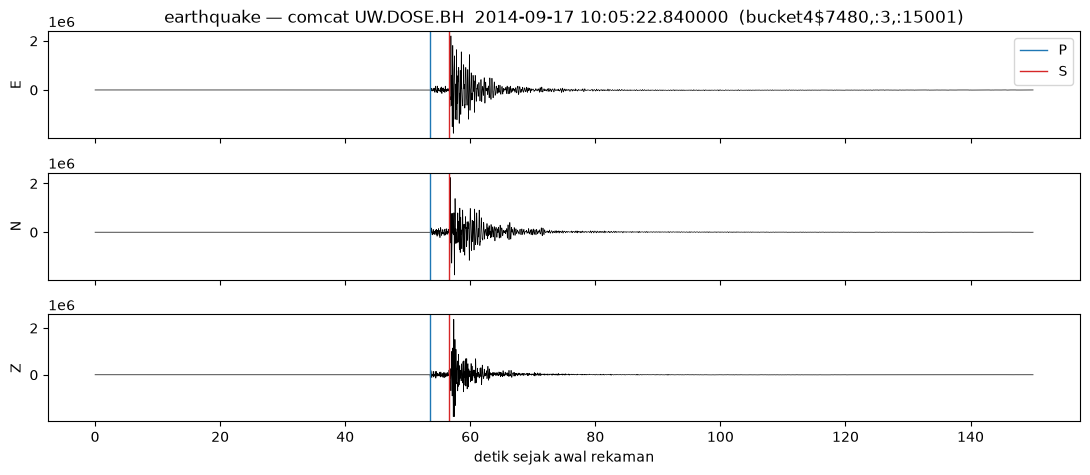

dibaca 360 KB lewat WebHDFS dalam 0.02 s, dtype=float64, shape=(3, 15001)


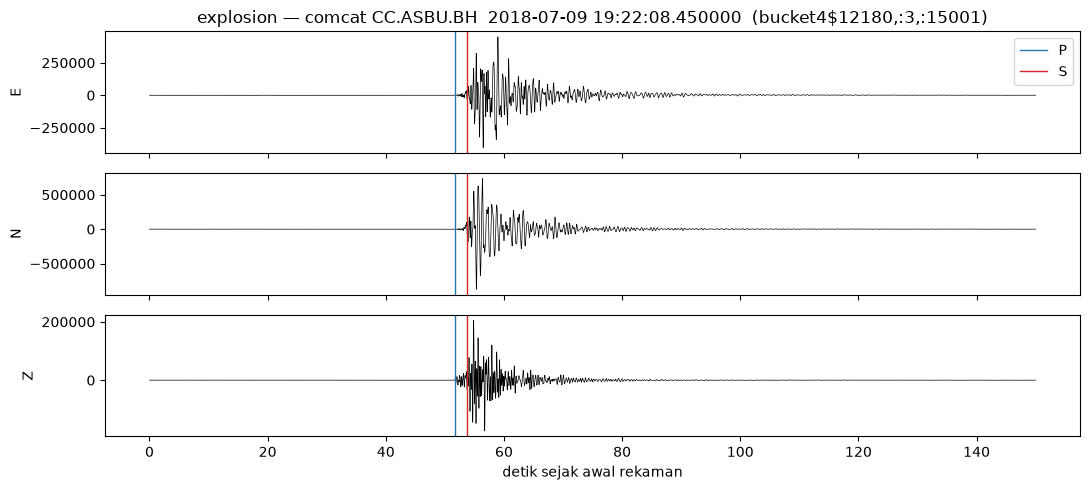

dibaca 360 KB lewat WebHDFS dalam 0.01 s, dtype=float64, shape=(3, 15001)


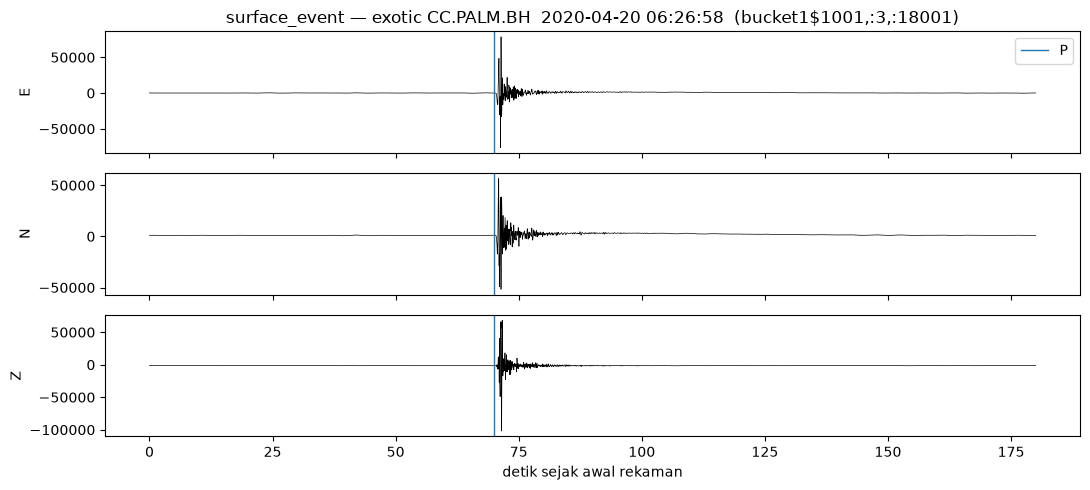

dibaca 432 KB lewat WebHDFS dalam 0.01 s, dtype=float64, shape=(3, 18001)


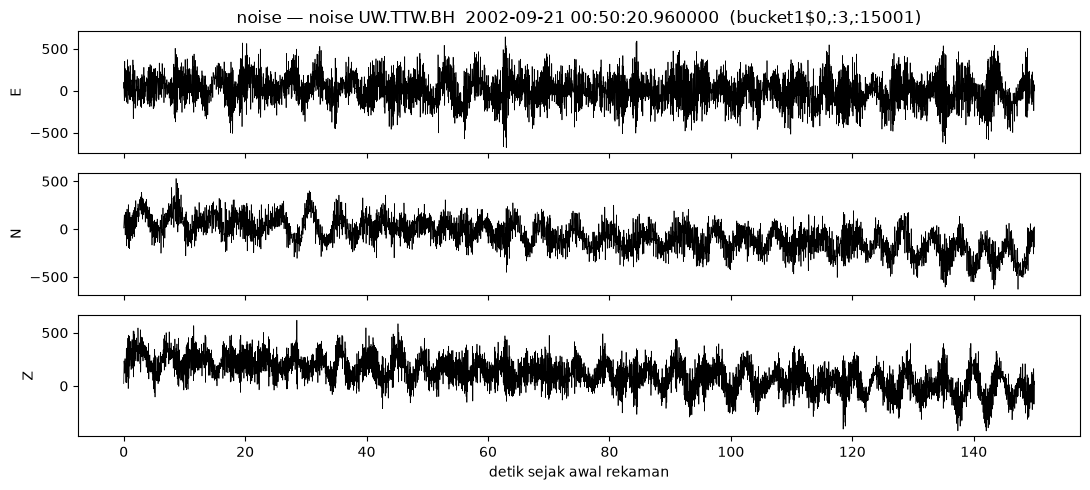

dibaca 360 KB lewat WebHDFS dalam 0.01 s, dtype=float64, shape=(3, 15001)


In [26]:
def pick(d, cond, order_col=None):
    df = parsed[d].filter(cond).filter(F.col('station_channel_code').isin('HH', 'BH'))
    if order_col: df = df.orderBy(F.desc(order_col))
    return df.first()
examples = {
    'earthquake':    ('comcat', pick('comcat', "source_type='earthquake' AND trace_missing_channel=0 AND preferred_source_magnitude BETWEEN 3 AND 4", 'snr_z')),
    'explosion':     ('comcat', pick('comcat', "source_type='explosion' AND trace_missing_channel=0", 'snr_z')),
    'surface_event': ('exotic', pick('exotic', "source_type='surface event' AND snr_z IS NOT NULL", 'snr_z')),
    'noise':         ('noise',  pick('noise',  "source_type='noise'")),
}
for label, (d, r) in examples.items():
    t0 = time.time(); x = h5[d]['data'][r.bucket][r.row]; dt = time.time() - t0
    t = np.arange(x.shape[1]) / 100
    fig, ax = plt.subplots(3, 1, figsize=(11, 5), sharex=True)
    for i, comp in enumerate('ENZ'):
        ax[i].plot(t, x[i], lw=.5, color='k'); ax[i].set_ylabel(comp)
        for ph, c in (('P', 'tab:blue'), ('S', 'tab:red')):
            s = r.asDict().get(f'trace_{ph}_arrival_sample')
            if s is not None: ax[i].axvline(s / 100, color=c, lw=1, label=ph if i == 0 else None)
    ax[0].set_title(f'{label} — {d} {r.station_network_code}.{r.station_code}.{r.station_channel_code}  {r.trace_start_time}  ({r.trace_name})')
    if ax[0].get_legend_handles_labels()[0]: ax[0].legend(loc='upper right')
    ax[-1].set_xlabel('detik sejak awal rekaman'); fig.tight_layout()
    fig.savefig(f'{OUT_FIGS}/waveform_{label}.png', dpi=120); plt.show()
    print(f'dibaca {x.nbytes/1e3:.0f} KB lewat WebHDFS dalam {dt:.2f} s, dtype={x.dtype}, shape={x.shape}')

Garis biru = waktu tiba gelombang **P**, merah = **S** (dari metadata). Noise tidak punya keduanya. Exotic lebih panjang (180 s) dan P selalu di detik ke-70 — **ini beda bentuk yang harus diseragamkan di A2**, kalau tidak model bisa menebak kelas dari panjang array.

### B4. Cek komponen kosong langsung dari waveform (sampel)
Noise & Exotic tidak punya kolom `trace_missing_channel`. Kita cek 300 trace acak per dataset: komponen dianggap kosong kalau semua nilainya 0.

In [27]:
rng = np.random.default_rng(0)
emp = []
for d in DATASETS:
    p = parsed[d].select('bucket', 'row', 'station_channel_code').toPandas().sample(300, random_state=0).sort_values(['bucket', 'row'])
    for r in p.itertuples():
        x = h5[d]['data'][r.bucket][r.row]
        emp.append({'dataset': d, 'channel': r.station_channel_code, 'empty_components': int((np.abs(x).max(axis=1) == 0).sum())})
emp = pd.DataFrame(emp)
pd.crosstab([emp.dataset, emp.channel], emp.empty_components)

empty_components    0   1    2
dataset channel               
comcat  BH         88   0    0
        EH         75  11   86
        HH         39   1    0
exotic  BH         48   0    0
        EH         76   1  169
        HH          6   0    0
noise   BH         70   3   39
        EH        103   1   40
        HH         39   0    5

**Temuan (sampel 300 trace/dataset):**
- Sensor **EH** umumnya hanya 1 komponen (vertikal) di semua dataset → sifat alat, bukan kerusakan.
- Tapi di **Noise**, sensor BH/HH juga cukup sering punya 2 komponen kosong (±35% BH), sedangkan di ComCat hampir tidak pernah. Artinya *jumlah komponen kosong* ikut berbeda per kelas → **jalan pintas lain** untuk model. Di A2: pakai komponen Z saja atau samakan perlakuan komponen kosong.
- Untuk Noise & Exotic kita **hitung sendiri** `trace_missing_channel` dari waveform saat konversi (notebook 02), supaya kolom ini ada di semua dataset.

## C. Klasifikasi format data

In [28]:
elements = pd.DataFrame([
 ('Metadata CSV (3 file)', 'CSV teks, tabel baris × kolom, header', 'Structured',
  'Skema tetap: setiap baris = 1 rekaman, setiap kolom punya nama & tipe. Langsung bisa di-query SQL/Spark'),
 ('trace_snr_db', 'String "E|N|Z" di dalam kolom CSV', 'Semi-structured',
  'Satu sel berisi list 3 angka dengan pemisah sendiri → harus di-parse jadi 3 kolom'),
 ('trace_name', 'String "bucketK$row,:3,:n" di dalam kolom CSV', 'Semi-structured',
  'Pointer berpola (mini-bahasa slicing NumPy) ke lokasi waveform di HDF5'),
 ('HDF5 container', 'Binary, hierarkis (group /data, /data_format), self-describing', 'Semi-structured (wadah)',
  'Punya struktur pohon & atribut (dtype, shape, component_order), tapi bukan tabel'),
 ('Waveform (isi HDF5)', 'Array float64 (N, 3, 15001|18001) — deret waktu 100 Hz', 'Unstructured',
  '45,003 angka per rekaman tanpa arti per-kolom; informasi (gempa/ledakan) harus diekstrak dengan pemrosesan sinyal/ML. ±86 GB = 99.9% volume'),
 ('lineage.jsonl', 'JSON Lines (1 objek JSON per baris)', 'Semi-structured',
  'Key-value dengan skema fleksibel; dibuat oleh pipeline kita untuk jejak asal-usul'),
], columns=['element', 'physical format', 'category', 'why'])
save_md(elements, 'data_elements', 'Elemen data & klasifikasi format'); elements

,element,physical format,category,why
0,Metadata CSV (3 file),"CSV teks, tabel baris × kolom, header",Structured,"Skema tetap: setiap baris = 1 rekaman, setiap ..."
1,trace_snr_db,"String ""E|N|Z"" di dalam kolom CSV",Semi-structured,Satu sel berisi list 3 angka dengan pemisah se...
2,trace_name,"String ""bucketK$row,:3,:n"" di dalam kolom CSV",Semi-structured,Pointer berpola (mini-bahasa slicing NumPy) ke...
3,HDF5 container,"Binary, hierarkis (group /data, /data_format),...",Semi-structured (wadah),"Punya struktur pohon & atribut (dtype, shape, ..."
4,Waveform (isi HDF5),"Array float64 (N, 3, 15001|18001) — deret wakt...",Unstructured,"45,003 angka per rekaman tanpa arti per-kolom;..."
5,lineage.jsonl,JSON Lines (1 objek JSON per baris),Semi-structured,Key-value dengan skema fleksibel; dibuat oleh ...


## D. Kolom mana yang dipakai model? (walau modelling baru di A2)

**Jawaban singkat: fitur model diambil dari *waveform*, bukan dari kolom CSV.** Kita **tidak** memotong ComCat/Exotic ke 11 kolom Noise — karena 11 kolom itu pun bukan fitur.

Kolom CSV hanya dipakai sebagai: **label** (`source_type`), **kunci** untuk mengambil waveform (`dataset`, `trace_name`), **split** train/test (`event_id`), dan **validasi/EDA**.

Kenapa kolom CSV berbahaya sebagai fitur? Karena **keberadaan kolomnya saja sudah membocorkan kelas** (*leakage*). Buktinya di bawah: tanpa model apa pun, satu aturan sederhana sudah hampir sempurna — padahal di dunia nyata, saat sinyal baru masuk, info itu belum ada (magnitudo & pick dihitung analis *setelah* tahu itu gempa).

In [29]:
TO4 = {'earthquake': 'earthquake', 'explosion': 'explosion', 'surface event': 'surface_event', 'noise': 'noise'}
allm = None
for d in DATASETS:
    x = parsed[d].withColumn('dataset', F.lit(d))
    allm = x if allm is None else allm.unionByName(x, allowMissingColumns=True)
lab = F.create_map([F.lit(v) for kv in TO4.items() for v in kv])
allm = allm.withColumn('label', lab[F.col('source_type')]).filter('label IS NOT NULL')
checks = {
  'punya trace_P_arrival_sample': F.col('trace_P_arrival_sample').isNotNull(),
  'punya magnitudo (preferred_source_magnitude)': F.col('preferred_source_magnitude').isNotNull(),
  'n_samples = 18001': F.col('n_samples') == 18001,
  'punya event_id': F.col('event_id').isNotNull(),
}
out = []
for name, cond in checks.items():
    t = allm.groupBy(cond.alias('rule')).pivot('label').count().fillna(0).toPandas()
    t.insert(0, 'aturan', name); out.append(t)
leak = pd.concat(out).reset_index(drop=True); leak

,aturan,rule,earthquake,explosion,noise,surface_event
0,punya trace_P_arrival_sample,True,163064,15875,0,8804
1,punya trace_P_arrival_sample,False,0,0,51017,108
2,punya magnitudo (preferred_source_magnitude),True,163064,15875,0,0
3,punya magnitudo (preferred_source_magnitude),False,0,0,51017,8912
4,n_samples = 18001,True,0,0,0,8912
5,n_samples = 18001,False,163064,15875,51017,0
6,punya event_id,True,163064,15875,0,8912
7,punya event_id,False,0,0,51017,0


Cara membaca: baris `rule=False` untuk "punya trace_P_arrival_sample" berisi **hampir semua noise** → aturan *"tidak ada P → noise"* benar ~100%. `n_samples=18001` → selalu surface_event. Punya magnitudo → tidak pernah surface_event/noise. Model yang "belajar" ini terlihat hebat di tes, tapi **gagal total di dunia nyata**.

Karena itu setiap kolom diberi **peran**:

In [30]:
save_md(leak, 'leakage_evidence', 'Bukti leakage: aturan sederhana dari kolom metadata vs kelas',
        'Keberadaan kolom (bukan isi sinyal) sudah memisahkan kelas → kolom-kolom ini dilarang jadi fitur model.')
ROLE = {
 'trace_name': 'key (+ dataset)', 'source_type': 'label', 'source_type_pnsn_label': 'label correction',
 'event_id': 'split (train/test per event) + graph', 'trace_sampling_rate_hz': 'validation',
 'trace_missing_channel': 'cleaning flag', 'trace_has_offset': 'cleaning flag', 'trace_snr_db': 'cleaning/quality (not feature)',
 'trace_start_time': 'EDA / time split', 'station_channel_code': 'EDA; ablation only (sensor type)',
 'station_network_code': 'EDA; NOT feature (shortcut: CC volcano network ≈ 34% Exotic)',
 'station_code': 'EDA + graph node', 'station_location_code': 'EDA',
 'station_latitude_deg': 'EDA map + graph', 'station_longitude_deg': 'EDA map + graph', 'station_elevation_m': 'EDA',
}
def role(c):
    if c in ROLE: return ROLE[c]
    if c.startswith('source_') or c.startswith('preferred_'): return 'EDA/dashboard only — NOT feature (only exists for catalogued events)'
    return 'NOT feature (pick info exists only when there is an event → leakage); P arrival may be used for window alignment in A2 with care'
roles = cmp[['column', 'group', 'comcat', 'exotic', 'noise']].assign(role=lambda t: t.column.map(role))
save_md(roles, 'column_roles', 'Peran kolom',
        'Model utama A2 = waveform saja (3 × 15,001 angka, dipotong seragam). Kolom metadata tidak menjadi fitur utama.'); roles

,column,group,comcat,exotic,noise,role
0,source_type,label,✓,✓,✓,label
1,station_network_code,station,✓,✓,✓,EDA; NOT feature (shortcut: CC volcano network...
2,station_channel_code,station,✓,✓,✓,EDA; ablation only (sensor type)
3,station_code,station,✓,✓,✓,EDA + graph node
4,station_location_code,station,✓,✓,✓,EDA
5,station_latitude_deg,station,✓,✓,✓,EDA map + graph
6,station_longitude_deg,station,✓,✓,✓,EDA map + graph
7,station_elevation_m,station,✓,✓,✓,EDA
8,trace_name,trace,✓,✓,✓,key (+ dataset)
9,trace_sampling_rate_hz,trace,✓,✓,✓,validation


## E. Kamus data (README tiap kolom)
Arti kolom dari README & paper PNW-ML (format SeisBench).

In [31]:
MEANING = {
 'event_id': 'ID kejadian di katalog (mis. uw10564613, pnsn3166678). 1 event direkam banyak stasiun',
 'source_origin_time': 'Waktu terjadinya kejadian (UTC)', 'source_latitude_deg': 'Lintang episenter', 'source_longitude_deg': 'Bujur episenter',
 'source_type': 'Jenis kejadian = LABEL (earthquake, explosion, surface event, sonic boom, thunder, plane crash, noise)',
 'source_depth_km': 'Kedalaman hiposenter (km)', 'preferred_source_magnitude': 'Magnitudo utama',
 'preferred_source_magnitude_type': 'Jenis magnitudo: ml (lokal), md (durasi), mh (manual)',
 'preferred_source_magnitude_uncertainty': 'Ketidakpastian magnitudo', 'source_depth_uncertainty_km': 'Ketidakpastian kedalaman (km)',
 'source_horizontal_uncertainty_km': 'Ketidakpastian lokasi horizontal (km)',
 'station_network_code': 'Kode jaringan seismik (UW, CC, PB, ...)', 'station_channel_code': 'Tipe sensor: EH short-period, BH broadband, HH broadband high-rate',
 'station_code': 'Kode stasiun', 'station_location_code': 'Kode lokasi sensor di stasiun ("--" = kosong)',
 'station_latitude_deg': 'Lintang stasiun', 'station_longitude_deg': 'Bujur stasiun', 'station_elevation_m': 'Elevasi stasiun (m)',
 'trace_name': 'Alamat waveform di HDF5: bucketK$baris,:3,:jumlah_sampel', 'trace_sampling_rate_hz': 'Sampel per detik (100)',
 'trace_start_time': 'Waktu mulai rekaman (UTC)', 'trace_S_arrival_sample': 'Indeks sampel tibanya gelombang S',
 'trace_P_arrival_sample': 'Indeks sampel tibanya gelombang P', 'trace_S_arrival_uncertainty_s': 'Ketidakpastian pick S (detik)',
 'trace_P_arrival_uncertainty_s': 'Ketidakpastian pick P (detik)', 'trace_P_polarity': 'Arah gerak awal P: positive/negative/undecidable',
 'trace_S_onset': 'Awal S: impulsive (tajam) / emergent (landai)', 'trace_P_onset': 'Awal P: impulsive / emergent',
 'trace_snr_db': 'Signal-to-noise ratio per komponen "E|N|Z" (dB)', 'source_type_pnsn_label': 'Kode tipe kejadian di database PNSN AQMS (eq, px, su, ...)',
 'source_local_magnitude': 'Magnitudo lokal (ML)', 'source_local_magnitude_uncertainty': 'Ketidakpastian ML',
 'source_duration_magnitude': 'Magnitudo durasi (Md)', 'source_duration_magnitude_uncertainty': 'Ketidakpastian Md',
 'source_hand_magnitude': 'Magnitudo manual (Mh)', 'trace_missing_channel': 'Jumlah komponen kosong (0–2)',
 'trace_has_offset': 'Ada offset (loncatan) yang terlihat di rekaman (0/1)',
}
FMT = {'trace_snr_db': 'semi-structured (list in string)', 'trace_name': 'semi-structured (pointer)'}
first = {d: meta[d].first().asDict() for d in DATASETS}
dd = pd.DataFrame([{
    'column': c, 'meaning': MEANING[c],
    'type': next(dict(meta[d].dtypes)[c] for d in DATASETS if c in meta[d].columns),
    'files': ', '.join(d for d in DATASETS if c in meta[d].columns),
    'null_% (comcat/exotic/noise)': ' / '.join('–' if pd.isna(nulls.loc[c, d]) else f'{nulls.loc[c, d]:g}' for d in DATASETS),
    'example': str(next(first[d][c] for d in DATASETS if c in first[d])),
    'format': FMT.get(c, 'structured'), 'role': role(c)} for c in cmp.column])
waveform_row = pd.DataFrame([{'column': '(HDF5) data/bucketK[row]', 'meaning': 'Rekaman sinyal 3 komponen E,N,Z, 100 Hz, 150 s (180 s exotic)',
    'type': 'float64[3][15001|18001]', 'files': 'comcat, exotic, noise', 'null_% (comcat/exotic/noise)': '0',
    'example': 'array (3, 15001)', 'format': 'unstructured', 'role': 'MODEL INPUT (A2)'}])
dd = pd.concat([dd, waveform_row], ignore_index=True)
save_md(dd, 'data_dictionary', 'Kamus data PNW-ML (subset ComCat + Exotic + Noise)'); dd

,column,meaning,type,files,null_% (comcat/exotic/noise),example,format,role
0,source_type,"Jenis kejadian = LABEL (earthquake, explosion,...",string,"comcat, exotic, noise",0 / 0 / 0,earthquake,structured,label
1,station_network_code,"Kode jaringan seismik (UW, CC, PB, ...)",string,"comcat, exotic, noise",0 / 0 / 0,UW,structured,EDA; NOT feature (shortcut: CC volcano network...
2,station_channel_code,"Tipe sensor: EH short-period, BH broadband, HH...",string,"comcat, exotic, noise",0 / 0 / 0,BH,structured,EDA; ablation only (sensor type)
3,station_code,Kode stasiun,string,"comcat, exotic, noise",0 / 0 / 0,GNW,structured,EDA + graph node
4,station_location_code,"Kode lokasi sensor di stasiun (""--"" = kosong)",string,"comcat, exotic, noise",0 / 0 / 0,--,structured,EDA
5,station_latitude_deg,Lintang stasiun,double,"comcat, exotic, noise",0 / 0 / 0,47.564,structured,EDA map + graph
6,station_longitude_deg,Bujur stasiun,double,"comcat, exotic, noise",0 / 0 / 0,-122.825,structured,EDA map + graph
7,station_elevation_m,Elevasi stasiun (m),double,"comcat, exotic, noise",0 / 0 / 0,220.0,structured,EDA
8,trace_name,"Alamat waveform di HDF5: bucketK$baris,:3,:jum...",string,"comcat, exotic, noise",0 / 0 / 0,"bucket4$0,:3,:15001",semi-structured (pointer),key (+ dataset)
9,trace_sampling_rate_hz,Sampel per detik (100),int,"comcat, exotic, noise",0 / 0 / 0,100,structured,validation


### Pertanyaan awal tentang data (U1–U7, U11, U12)

In [32]:
ua = pd.DataFrame([
 ('U1', 'Nama kolom', f"comcat {len(sets['comcat'])}, exotic {len(sets['exotic'])}, noise {len(sets['noise'])} kolom; magnitudo = 5 kolom terpisah (local/duration/hand + uncertainty)"),
 ('U2', 'Kolom Noise/Exotic = ComCat?', 'Tidak — bersarang noise ⊂ exotic ⊂ comcat'),
 ('U3', 'Label noise', "source_type ada, isinya 'noise' untuk semua baris"),
 ('U4', 'Jumlah baris', ', '.join(f"{r.dataset} {r.rows:,}" for r in summary.itertuples()) + ' (sama dengan proposal)'),
 ('U5', 'trace_name unik antar file?', 'Tidak — irisan comcat∩noise besar; + 395 duplikat di dalam noise'),
 ('U6', 'dtype waveform', 'float64'),
 ('U7', 'Struktur HDF5', f'data/bucketK (N,3,samples), contiguous, tanpa kompresi; component_order = {order["comcat"]}'),
 ('U11', 'Label PNSN', f'kode eq/lf/ex/px/qb/su/sn/uk (Tabel S2); {bad.n.sum()} rekaman ({ev_bad} event) tidak konsisten'),
 ('U12', 'SNR noise', 'Noise tidak punya kolom trace_snr_db sama sekali; ComCat/Exotic: nilai "nan" per komponen kosong'),
], columns=['id', 'question', 'answer'])
save_md(ua, 'initial_data_questions', 'Pertanyaan awal tentang data'); ua

,id,question,answer
0,U1,Nama kolom,"comcat 37, exotic 17, noise 11 kolom; magnitud..."
1,U2,Kolom Noise/Exotic = ComCat?,Tidak — bersarang noise ⊂ exotic ⊂ comcat
2,U3,Label noise,"source_type ada, isinya 'noise' untuk semua baris"
3,U4,Jumlah baris,"comcat 178,939, exotic 9,267, noise 51,017 (sa..."
4,U5,trace_name unik antar file?,Tidak — irisan comcat∩noise besar; + 395 dupli...
5,U6,dtype waveform,float64
6,U7,Struktur HDF5,"data/bucketK (N,3,samples), contiguous, tanpa ..."
7,U11,Label PNSN,kode eq/lf/ex/px/qb/su/sn/uk (Tabel S2); 467 r...
8,U12,SNR noise,Noise tidak punya kolom trace_snr_db sama seka...


## Ringkasan & keputusan sebelum cleaning

**Yang sekarang kita tahu:**
1. 3 CSV structured (37/17/11 kolom, bersarang), 3 HDF5 berisi waveform float64 (unstructured), urutan komponen ENZ.
2. Fitur model = waveform. Kolom metadata = label/kunci/split/EDA — terbukti bocor kalau jadi fitur.
3. Kunci join = `(dataset, trace_name)`.

**Keputusan sebelum cleaning:**
| # | Masalah | Usulan |
|---|---|---|
| 1 | Label ComCat tidak konsisten dengan kode PNSN (lihat A6) | **Diputuskan:** pemetaan Tabel S2; konflik earthquake↔explosion ikut PNSN (367 baris); PNSN di luar earthquake/explosion (su, sn, uk, qb) dibuang (100 baris) — lihat notebook 03 |
| 2 | Kelas di luar scope (sonic boom, thunder, plane crash) | Dibuang dari processed (tetap ada di raw) |
| 3 | 395 `trace_name` duplikat di Noise (790 baris) | **Diputuskan:** buang semua 790 baris (masih ada di metadata versi terbaru, dicek ulang 24-09-2026) |
| 4 | `trace_missing_channel` = 2 (28% ComCat, mayoritas EH) | **Pertahankan + flag** (sifat sensor, bukan rusak) |
| 5 | `trace_has_offset` = 1 (1,534 rekaman ComCat) | Pertahankan + flag, putuskan di A2 |
| 6 | Orphan waveform di HDF5 | Diabaikan otomatis (konversi dikendalikan metadata) |

In [33]:
spark.stop()